# Downscaling Tracts to Block Groups

This notebook measures how well three interpolation methods recover block-group population from tract totals, first in Delaware and then in Washington, DC. In the 2021 ACS, block groups nest inside tracts, and their estimates sum exactly to each tract's total. The block-group estimates therefore serve as the truth: each method sees only the tract counts, so every error it makes comes from how it divides a tract's population among the block groups inside it. A final section starts from block groups instead, downscaling them to census blocks and mapping their residents to buildings.

The methods differ in where they assume people live:

- **Area** (`area_interpolate`) spreads each tract's population evenly over the tract.
- **NLCD developed** (`masked_area_interpolate`) spreads it evenly over the tract's developed land, the pixels NLCD 2021 classifies as developed (classes 21–24).
- **Floor area** (`floor_area_interpolate`) spreads it over the tract's residential floor area: each building's footprint times its number of floors, estimated from building height in [Overture Maps](https://overturemaps.org/) data.

A fourth run, **footprint area**, calls `floor_area_interpolate` without heights, so every building counts as a single floor. Comparing it with floor area isolates what building height adds. Floor area is the most direct of these weights, since dwellings stack, but it is only as good as the heights and floor counts behind it. Most of Delaware's buildings are low; Washington's rowhouses and apartment buildings are taller, so the two places test whether height helps more where buildings rise.

In [16]:
import geopandas as gpd
import geosnap as gsp
import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import overturemaps
import pandas as pd
from matplotlib.lines import Line2D
from matplotlib.patches import Rectangle
from matplotlib.ticker import FuncFormatter, PercentFormatter

from tobler.area_weighted import area_interpolate
from tobler.dasymetric import (
    floor_area_dot_density,
    floor_area_interpolate,
    masked_area_interpolate,
)

%load_ext watermark
%watermark -v -d -u -p tobler,geopandas,geosnap,overturemaps -a 'eli knaap'

The watermark extension is already loaded. To reload it, use:
  %reload_ext watermark
Author: eli knaap

Last updated: 2026-11-18

Python implementation: CPython
Python version       : 3.13.9
IPython version      : 9.7.0

tobler      : 0.13.1.dev118+g58fb54026.d20261111
geopandas   : 1.1.1
geosnap     : 0.15.4.dev0+g08b0d60a8.d20251109
overturemaps: 2.1.0



## Setup

Four helpers load the data and run the methods, so both places go through identical steps. Census data come from the 2021 ACS through geosnap, projected to the local UTM zone so that areas are in square meters. Buildings come from Overture's building layer; we keep those classified as residential or left unclassified, dropping those known to serve another use. Many unclassified buildings are plainly not homes, so we also drop an unclassified building when it stands on land that Overture's land-use layer, drawn from OpenStreetMap, assigns to a use other than housing: military, education, medical, recreation, parks, construction, and the like, or developed land classed as commercial, retail, or industrial. A building classified as residential stays wherever it stands. Each building's number of floors is its height divided by a three-meter floor-to-floor height, rounded down, and at least one.

In [2]:
NLCD = "https://spatial-ucr.s3.amazonaws.com/nlcd/landcover/nlcd_landcover_2021.tif"
DEVELOPED = [21, 22, 23, 24]
floor_height = 3  # meters, floor to floor
heights = {"height_col": "height", "floor_height": floor_height}


def census(state_fips):
    """2021 ACS tracts and block groups, in the local UTM zone."""
    datastore = gsp.DataStore()
    tracts = gsp.io.get_acs(datastore, level="tract", state_fips=state_fips, years=2021)
    bgs = gsp.io.get_acs(datastore, level="bg", state_fips=state_fips, years=2021)
    crs = tracts.estimate_utm_crs()
    return tracts.to_crs(crs).set_index("geoid"), bgs.to_crs(crs).set_index("geoid")


def overture(theme, tracts):
    """One Overture theme within the tracts' bounding box, in longitude and latitude."""
    bounds = list(tracts.to_crs(4326).total_bounds)
    reader = overturemaps.record_batch_reader(theme, bounds, stac=True)
    return gpd.GeoDataFrame.from_arrow(reader.read_all()).set_crs(4326)


def residential_buildings(tracts):
    """Overture buildings inside the tracts that are residential or unclassified.

    Unclassified buildings on non-residential land are flagged in `nonresidential_land`.
    """
    bldgs = overture("building", tracts)
    bldgs = bldgs[bldgs.intersects(tracts.to_crs(4326).union_all())].to_crs(tracts.crs)
    # keep residential or unknown; i.e. drop anything *known* to be non-residential
    bldgs = bldgs[(bldgs["subtype"] == "residential") | bldgs["subtype"].isna()]
    bldgs = bldgs[["id", "subtype", "height", "num_floors", "geometry"]]

    land = overture("land_use", tracts).to_crs(tracts.crs)
    other_use = land["subtype"].notna() & ~land["subtype"].isin(["residential", "developed"])
    business = (land["subtype"] == "developed") & land["class"].isin(
        ["commercial", "retail", "industrial"]
    )
    points = gpd.GeoDataFrame(geometry=bldgs.representative_point())
    on_nonresidential = gpd.sjoin(
        points, land.loc[other_use | business, ["geometry"]], predicate="within"
    ).index
    return bldgs.assign(
        nonresidential_land=bldgs.index.isin(on_nonresidential) & bldgs["subtype"].isna()
    )


def building_profile(all_bldgs):
    """How many buildings the land-use filter drops, and how tall the rest are."""
    dropped = all_bldgs["nonresidential_land"]
    bldgs = all_bldgs[~dropped]
    floors = np.maximum(1, bldgs["height"].fillna(0) // floor_height)
    return pd.Series(
        {
            "unclassified": f"{all_bldgs['subtype'].isna().mean():.0%}",
            "dropped for land use": f"{dropped.sum():,}",
            "buildings kept": f"{len(bldgs):,}",
            "with a height": f"{bldgs['height'].notna().mean():.0%}",
            "counted as one floor": f"{(floors == 1).mean():.0%}",
            "five floors or more": f"{(floors >= 5).mean():.1%}",
            "floor area / footprint area": f"{(bldgs.area * floors).sum() / bldgs.area.sum():.2f}",
        }
    )


def estimate(tracts, bgs, bldgs, variables):
    """Downscale tract counts to block groups with each method."""
    return {
        "area": area_interpolate(tracts, bgs, extensive_variables=variables),
        "NLCD developed": masked_area_interpolate(
            tracts,
            bgs,
            raster=NLCD,
            pixel_values=DEVELOPED,
            extensive_variables=variables,
        ),
        "footprint area": floor_area_interpolate(
            tracts, bgs, bldgs, extensive_variables=variables
        ),
        "floor area": floor_area_interpolate(
            tracts, bgs, bldgs, extensive_variables=variables, **heights
        ),
    }

## Delaware

### Census data

We interpolate total population, housing units, and the four largest racial and ethnic groups. For every one of them, the block groups in each tract sum exactly to the tract's total.

In [3]:
variables = [
    "n_total_pop",
    "n_total_housing_units",
    "n_nonhisp_white_persons",
    "n_nonhisp_black_persons",
    "n_hispanic_persons",
    "n_asian_persons",
]

tracts, bgs = census("10")

bg_sums = bgs.groupby(bgs.index.str[:11])[variables].sum()
print(f"{len(tracts)} tracts, {len(bgs)} block groups")
(tracts[variables] - bg_sums).abs().max().rename("largest tract gap")

262 tracts, 706 block groups


n_total_pop                0.0
n_total_housing_units      0.0
n_nonhisp_white_persons    0.0
n_nonhisp_black_persons    0.0
n_hispanic_persons         0.0
n_asian_persons            0.0
Name: largest tract gap, dtype: float64

### Buildings

In [4]:
all_bldgs = residential_buildings(tracts)
bldgs = all_bldgs[~all_bldgs["nonresidential_land"]]
building_profile(all_bldgs).to_frame("Delaware")

,Delaware
unclassified,89%
dropped for land use,"13,655"
buildings kept,"409,060"
with a height,83%
counted as one floor,91%
five floors or more,0.1%
floor area / footprint area,1.17


Overture leaves 89% of these buildings unclassified, and the land-use filter drops 13,655 of them, leaving 409,060. Most of those kept are low. At three meters per floor, 91% of them count as a single floor, and residential floor area exceeds footprint area by only 17%. Buildings without a height count as one floor.

### Interpolation

In [5]:
estimates = estimate(tracts, bgs, bldgs, variables)

Every method conserves each tract's total, so an overestimate in one block group is matched by underestimates elsewhere in the same tract.

In [6]:
pd.Series({m: e["n_total_pop"].sum() for m, e in estimates.items()}, name="total population")

area              981891.998652
NLCD developed    981892.001734
footprint area    981892.000002
floor area        981892.000002
Name: total population, dtype: float64

### Relative error

For each block group, the relative error is (estimate − observed) / observed. It is undefined for the 6 block groups with no population, which we drop. Because tract totals are conserved, half the sum of absolute errors counts the people placed in the wrong block group; dividing by the state's population gives the share misplaced.

In [7]:
observed = bgs["n_total_pop"]
populated = observed > 0
rel = pd.DataFrame(
    {m: (e["n_total_pop"] - observed)[populated] / observed[populated] for m, e in estimates.items()}
)


def summarize(est, obs):
    err = est - obs
    r = (err[obs > 0] / obs[obs > 0]).abs()
    return pd.Series(
        {
            "median |relative error|": r.median(),
            "90th percentile |relative error|": r.quantile(0.9),
            "within 10%": (r <= 0.10).mean(),
            "within 25%": (r <= 0.25).mean(),
            "share of people misplaced": err.abs().sum() / 2 / obs.sum(),
        }
    )


summary = pd.DataFrame({m: summarize(e["n_total_pop"], observed) for m, e in estimates.items()})
summary.style.format("{:.1%}")

,area,NLCD developed,footprint area,floor area
median |relative error|,38.8%,27.1%,22.2%,21.8%
90th percentile |relative error|,92.2%,76.7%,63.0%,62.8%
within 10%,15.4%,20.4%,25.9%,26.3%
within 25%,33.9%,46.4%,54.4%,55.0%
share of people misplaced,22.2%,16.3%,12.9%,12.9%


Each restriction on where people can live reduces the error. Spreading population evenly over each tract misplaces 22% of Delawareans; restricting it to developed land cuts that to 16%, and restricting it to residential buildings cuts it to 13%. Over the same steps, the median block group's error falls from 39% to 22%.

Counting floors changes nothing at this precision: floor area and footprints each misplace 12.9% of people. With 91% of buildings counted as a single floor, the two weightings differ only where taller buildings stand.

The curves below show the full distribution of errors. They start at about 3% because 19 populated block groups are the only block group in their tract, and every method recovers those exactly.

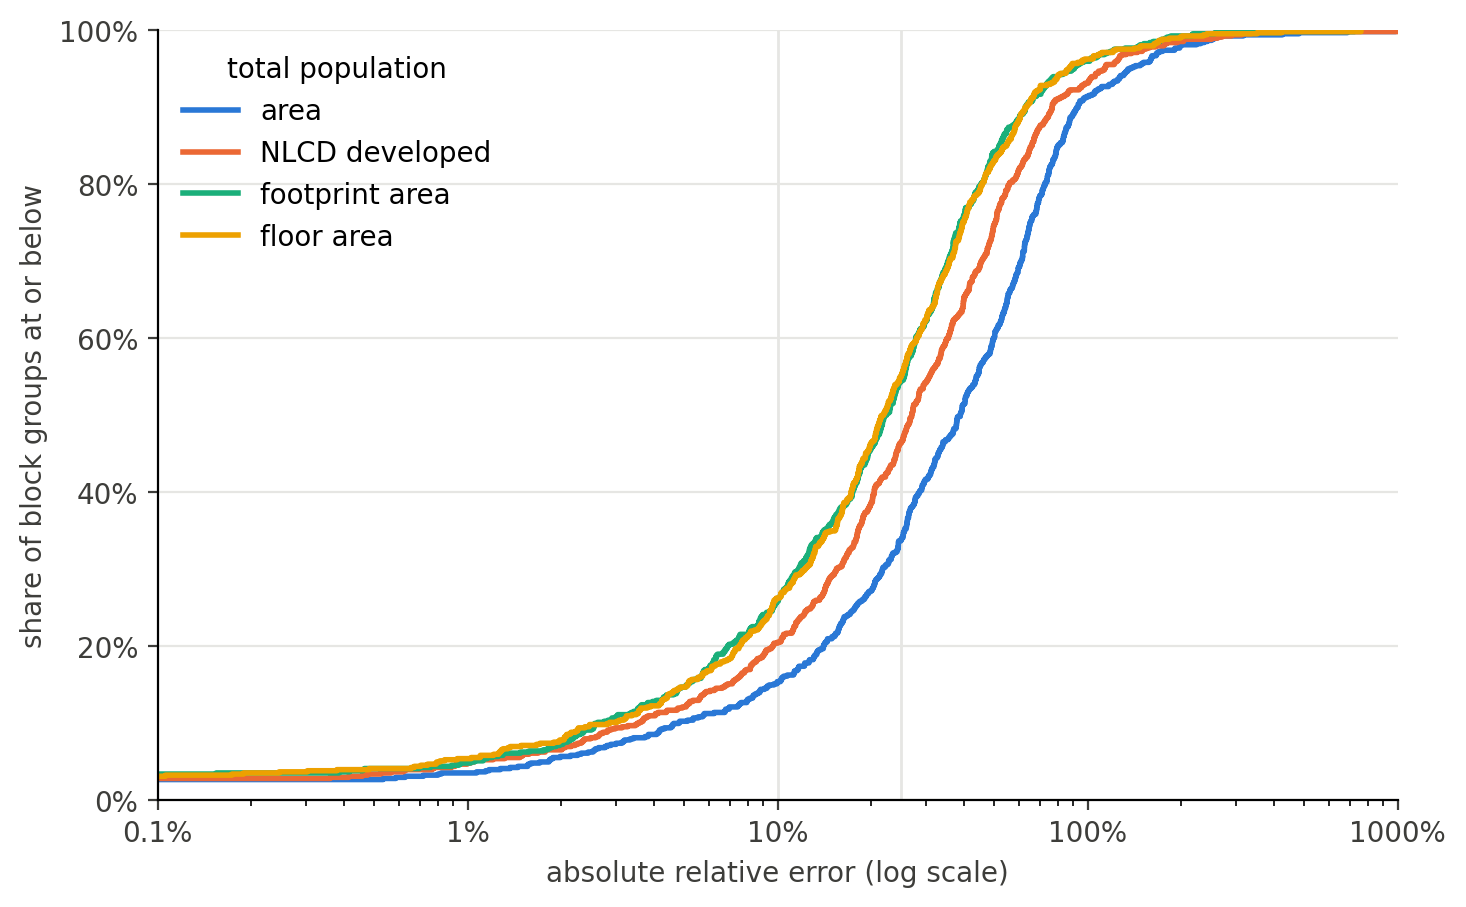

In [8]:
colors = {
    "area": "#2a78d6",
    "NLCD developed": "#eb6834",
    "footprint area": "#1baf7a",
    "floor area": "#eda100",
}
ink, grid = "#3d3d3a", "#e6e6e3"

fig, ax = plt.subplots(figsize=(8, 5))
for method, color in colors.items():
    r = np.sort(rel[method].abs().to_numpy())
    ax.step(r, np.arange(1, len(r) + 1) / len(r), where="post", color=color, lw=2, label=method)
for x in (0.10, 0.25):
    ax.axvline(x, color=grid, lw=1, zorder=0)
ax.set_xscale("log")
ax.set_xlim(0.001, 10)
ax.set_ylim(0, 1)
ax.xaxis.set_major_formatter(FuncFormatter(lambda x, _: f"{x:.0%}" if x >= 0.01 else f"{x:.1%}"))
ax.yaxis.set_major_formatter(PercentFormatter(1.0))
ax.set_xlabel("absolute relative error (log scale)", color=ink)
ax.set_ylabel("share of block groups at or below", color=ink)
ax.grid(axis="y", color=grid, lw=0.8)
ax.set_axisbelow(True)
ax.tick_params(colors=ink)
for side in ("top", "right"):
    ax.spines[side].set_visible(False)
ax.legend(frameon=False, loc="upper left", title="total population")
plt.show()

The maps show where each method errs. Red marks block groups it overestimates, blue those it underestimates; errors beyond ±100% share the end colors, and gray marks the block groups with no population.

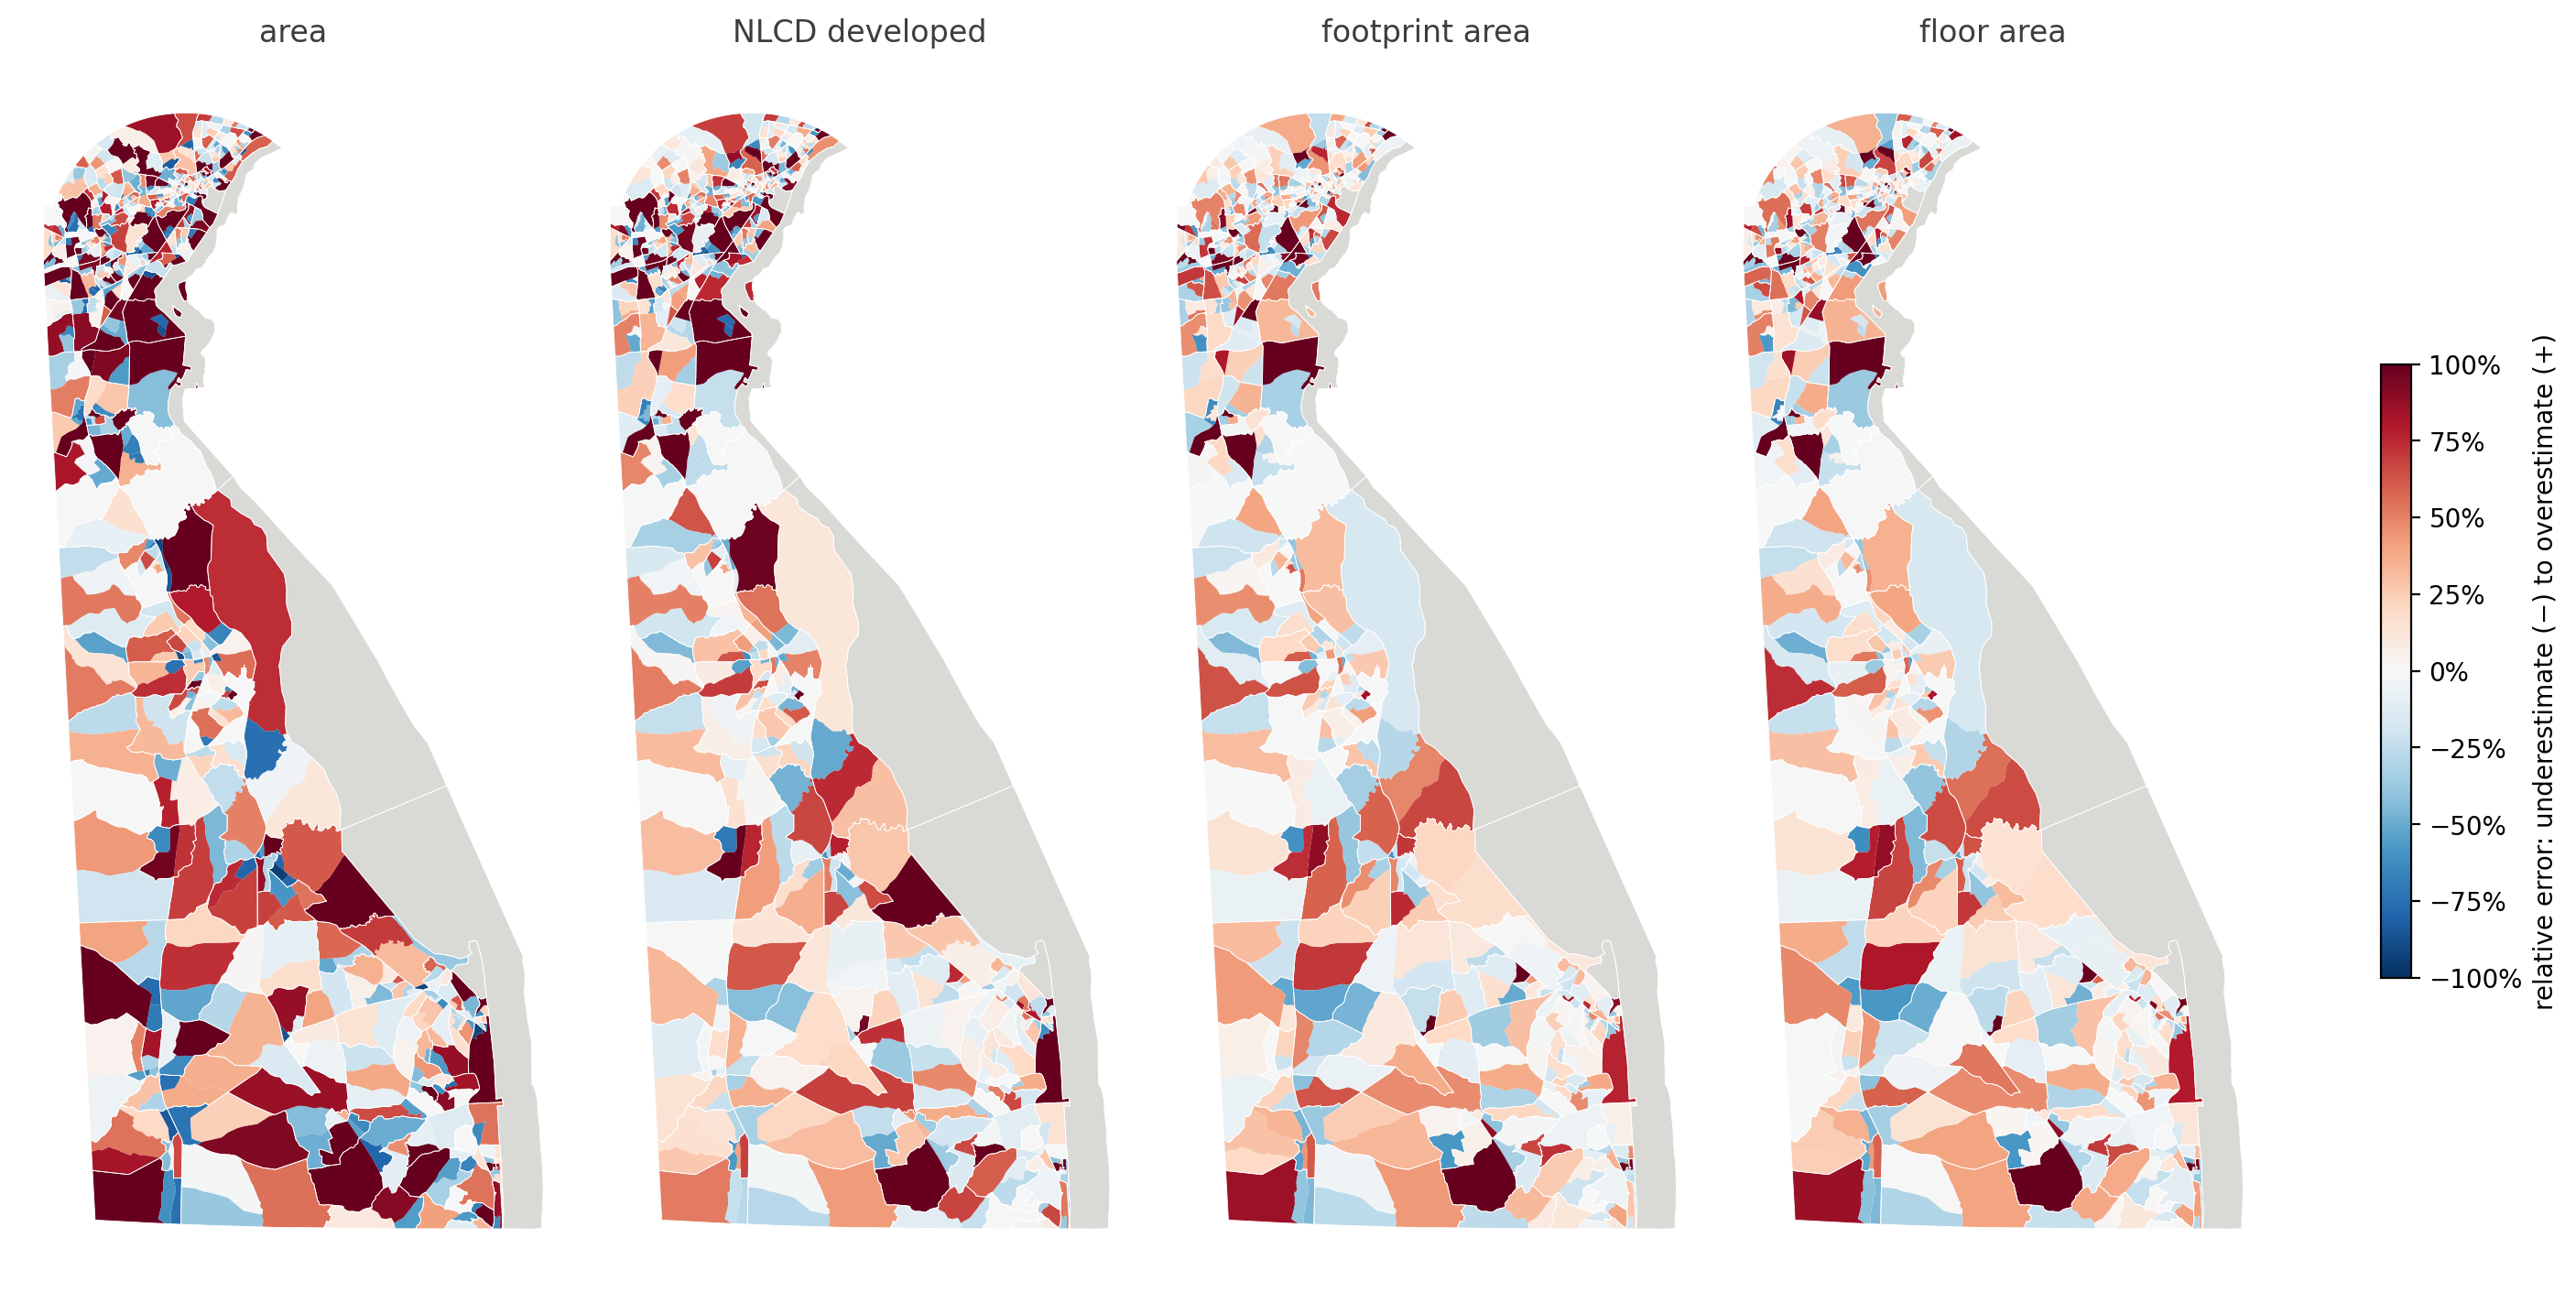

In [9]:
fig, axes = plt.subplots(1, 4, figsize=(14, 7), layout="constrained")
for ax, method in zip(axes, colors):
    bgs.assign(rel=rel[method].clip(-1, 1)).plot(
        "rel", ax=ax, cmap="RdBu_r", vmin=-1, vmax=1, missing_kwds={"color": "#d9d9d6"}
    )
    tracts.boundary.plot(ax=ax, color="white", lw=0.3)
    ax.set_title(method, color=ink)
    ax.set_axis_off()
fig.colorbar(
    mpl.cm.ScalarMappable(norm=mpl.colors.Normalize(-1, 1), cmap="RdBu_r"),
    ax=axes,
    shrink=0.5,
    format=PercentFormatter(1.0),
    label="relative error: underestimate (−) to overestimate (+)",
)
plt.show()

### Other variables

Many block groups have no residents in a given racial or ethnic group, so relative error is undefined for them. The share misplaced has no such problem, and it compares the methods across all six variables.

In [10]:
def share_misplaced(est, obs):
    return (est - obs).abs().sum() / 2 / obs.sum()


by_variable = pd.DataFrame(
    {m: {v: share_misplaced(e[v], bgs[v]) for v in variables} for m, e in estimates.items()}
)
by_variable.style.format("{:.1%}")

,area,NLCD developed,footprint area,floor area
n_total_pop,22.2%,16.3%,12.9%,12.9%
n_total_housing_units,22.1%,15.7%,12.3%,12.2%
n_nonhisp_white_persons,21.1%,15.7%,12.6%,13.1%
n_nonhisp_black_persons,32.6%,28.9%,26.0%,25.6%
n_hispanic_persons,35.9%,32.1%,30.2%,30.3%
n_asian_persons,40.0%,37.1%,35.7%,35.1%


Area weighting is the least accurate and the building weightings the most accurate for every variable. The racial and ethnic groups are harder to place than total population, and the smaller the group, the larger the error: with footprints, 13% of white residents land in the wrong block group, against 26% of Black, 30% of Hispanic, and 36% of Asian residents. The gain from buildings shrinks in step. Every method divides each group among a tract's block groups with the same weights it uses for total population, so none of them can see segregation within a tract.

## Washington, DC

Washington is denser and taller than Delaware, a city of rowhouses and apartment buildings, so building height has more to add. Its block groups nest inside its tracts as Delaware's do.

In [11]:
dc_tracts, dc_bgs = census("11")

dc_sums = dc_bgs.groupby(dc_bgs.index.str[:11])[variables].sum()
print(f"{len(dc_tracts)} tracts, {len(dc_bgs)} block groups")
print(f"largest tract gap: {(dc_tracts[variables] - dc_sums).abs().max().max():g}")

dc_all = residential_buildings(dc_tracts)
dc_bldgs = dc_all[~dc_all["nonresidential_land"]]
pd.DataFrame({"Delaware": building_profile(all_bldgs), "Washington, DC": building_profile(dc_all)})

206 tracts, 571 block groups
largest tract gap: 0


,Delaware,"Washington, DC"
unclassified,89%,35%
dropped for land use,"13,655","7,644"
buildings kept,"409,060","161,033"
with a height,83%,34%
counted as one floor,91%,83%
five floors or more,0.1%,0.9%
floor area / footprint area,1.17,2.28


Overture classifies far more of DC's buildings: 35% are unclassified, against 89% in Delaware, and the land-use filter drops 7,644 of them. DC's buildings are also taller. In DC 0.9% of the buildings kept have five floors or more, against 0.1% in Delaware, and residential floor area is 2.28 times footprint area, against 1.17. But only 34% of DC's buildings have a height, against 83% in Delaware, and a building without one counts as a single floor. The missing heights are not spread evenly:

In [12]:
dc_floors = np.maximum(1, dc_bldgs["height"].fillna(0) // floor_height)
known = dc_bldgs["height"].notna()
size = pd.qcut(
    dc_bldgs.area, 5, labels=["smallest fifth", "second", "third", "fourth", "largest fifth"]
).rename("footprint size")
counted = dc_bldgs["num_floors"].notna()
print(f"height or floor count: {(known | counted).mean():.0%} of buildings")
pd.DataFrame(
    {
        "with a height": known.groupby(size, observed=True).mean(),
        "median floors from height": dc_floors[known].groupby(size[known], observed=True).median(),
        "with a floor count": counted.groupby(size, observed=True).mean(),
        "median floor count": dc_bldgs["num_floors"].groupby(size, observed=True).median(),
    }
).style.format("{:.0%}", subset=["with a height", "with a floor count"]).format(
    "{:.0f}", subset=["median floors from height", "median floor count"]
)

height or floor count: 59% of buildings


,with a height,median floors from height,with a floor count,median floor count
footprint size,,,,
smallest fifth,16%,1,35%,2
second,17%,1,46%,2
third,19%,1,43%,2
fourth,44%,1,34%,2
largest fifth,74%,2,22%,2


Nearly three-quarters of the largest footprints have a height, but only 16% of the smallest. Below the largest fifth, the typical building counts as one floor either way: most have no height, and the heights the rest have round down, at the median, to a single three-meter floor. Overture's `num_floors` field, a recorded floor count, puts the median building at two floors in every size class. Counting every missing height as one floor therefore shifts each tract's population toward its large buildings, which more often have a height. We add a fifth run, **floor area, gaps filled**, that uses Overture's floor count where it records one and the height where it does not, and counts a building with neither as two floors. Together the two fields cover 59% of DC's buildings.

In [13]:
dc_estimates = estimate(dc_tracts, dc_bgs, dc_bldgs, variables)

# recorded floor counts first, heights where there is no count, two floors where neither
gaps_filled = {**heights, "floors_col": "num_floors", "default_floors": 2}
dc_estimates["floor area, gaps filled"] = floor_area_interpolate(
    dc_tracts, dc_bgs, dc_bldgs, extensive_variables=variables, **gaps_filled
)

dc_observed = dc_bgs["n_total_pop"]
dc_summary = pd.DataFrame(
    {m: summarize(e["n_total_pop"], dc_observed) for m, e in dc_estimates.items()}
)
dc_summary.style.format("{:.1%}")

,area,NLCD developed,footprint area,floor area,"floor area, gaps filled"
median |relative error|,30.1%,27.8%,22.4%,21.4%,21.5%
90th percentile |relative error|,88.3%,82.9%,64.9%,63.8%,65.0%
within 10%,19.5%,21.3%,27.0%,24.0%,25.9%
within 25%,44.1%,46.1%,54.2%,55.0%,54.6%
share of people misplaced,20.1%,18.6%,14.3%,14.4%,13.7%


The first three methods rank as they do in Delaware: area weighting misplaces 20.1% of DC's residents, developed land 18.6%, and footprints 14.3%. Counting floors from the heights as given lowers the median block group's error, from 22.4% to 21.4%, but misplaces slightly more people, 14.4%, because the large buildings gain floors that the small ones, lacking heights, do not. With the gaps filled, floor area misplaces 13.7%, the least of the five. Whether floor area beats footprints therefore depends on the building data: with the heights Overture provides it does no better, and with the gaps filled it does better, by 0.6 percentage points of the population.

### Where the tall buildings are

If height helps, it should help most in the tracts where tall buildings hold much of the floor area. We group the tracts by the share of their floor area in buildings of five floors or more, leaving out the tracts with a single block group, which every method recovers exactly.

The last column is a benchmark. It splits each tract's population by its block groups' actual housing-unit counts, taken from the same ACS table we are trying to recover. No building layer can know those counts, but they show how well people would be placed by a weight that located every dwelling exactly.

In [14]:
dc_tract = dc_bgs.index.str[:11]
points = gpd.GeoDataFrame(geometry=dc_bldgs.representative_point())
tract_of = gpd.sjoin(points, dc_tracts[["geometry"]], predicate="within")["geoid"]
dc_floor_area = dc_bldgs.area * dc_floors
tall_floor_area = dc_floor_area.where(dc_floors >= 5, 0)
tall_share = (
    (tall_floor_area.groupby(tract_of).sum() / dc_floor_area.groupby(tract_of).sum())
    .reindex(dc_tracts.index)
    .fillna(0)
)

n_bgs = dc_bgs.groupby(dc_tract).size()
multi = n_bgs.index[n_bgs > 1]
tall = pd.Series(
    np.select([tall_share == 0, tall_share < 0.25], ["none", "under 25%"], "25% or more"),
    index=dc_tracts.index,
    name="floor area in tall buildings",
).loc[multi]


def misplaced_by(est, obs, groups):
    """Share of people misplaced within each group of tracts."""
    tract = obs.index.str[:11]
    err = (est - obs).abs().groupby(tract).sum() / 2
    return err.groupby(groups).sum() / obs.groupby(tract).sum().groupby(groups).sum()


units = dc_bgs["n_total_housing_units"]
by_units = (
    dc_tracts["n_total_pop"].reindex(dc_tract).to_numpy()
    * (units / units.groupby(dc_tract).transform("sum")).fillna(0)
)

methods = ["area", "footprint area", "floor area", "floor area, gaps filled"]
by_tall = pd.DataFrame(
    {m: misplaced_by(dc_estimates[m]["n_total_pop"], dc_observed, tall) for m in methods}
)
by_tall["actual housing units"] = misplaced_by(by_units, dc_observed, tall)
by_tall.insert(0, "tracts", tall.value_counts())
print(f"split by actual housing units, all tracts: {share_misplaced(by_units, dc_observed):.1%} misplaced")
by_tall.loc[["none", "under 25%", "25% or more"]].style.format(
    "{:.1%}", subset=methods + ["actual housing units"]
)

split by actual housing units, all tracts: 7.9% misplaced


,tracts,area,footprint area,floor area,"floor area, gaps filled",actual housing units
floor area in tall buildings,,,,,,
none,67,17.3%,11.5%,12.3%,11.7%,7.4%
under 25%,48,20.2%,14.4%,13.8%,13.0%,9.1%
25% or more,80,24.1%,17.9%,17.8%,17.2%,7.7%


The tracts with the most tall buildings are the hardest for every method: footprints misplace 17.9% of their residents, against 11.5% in tracts with no tall buildings. Floor area narrows the gap only slightly. In the tall tracts, floor area from the heights as given misplaces 17.8%, about the same as footprints, and filling the gaps brings it to 17.2%. Its gain over footprints is 0.7 points there and 1.4 in the tracts with some tall buildings; in the tracts with none, it does slightly worse than footprints, 11.7% against 11.5%.

The benchmark shows that household size is not the obstacle. Split by their block groups' actual housing units, the tall tracts' residents would be misplaced at 7.7%, close to the 7.4% in tracts with no tall buildings: where buildings are tall, people follow dwellings about as closely as anywhere. Floor area with the gaps filled falls 9.5 points short of the benchmark in the tall tracts, against 4.3 in the tracts with none. If it falls short there, it must be misplacing the dwellings themselves. Interpolating housing units instead of people tests that directly:

In [15]:
units_by_tall = pd.DataFrame(
    {m: misplaced_by(dc_estimates[m]["n_total_housing_units"], units, tall) for m in methods}
)
units_by_tall.insert(0, "tracts", tall.value_counts())
units_by_tall.loc[["none", "under 25%", "25% or more"]].style.format("{:.1%}", subset=methods)

,tracts,area,footprint area,floor area,"floor area, gaps filled"
floor area in tall buildings,,,,,
none,67,17.4%,11.1%,11.3%,10.8%
under 25%,48,20.6%,14.3%,12.7%,12.9%
25% or more,80,24.3%,19.0%,18.0%,17.7%


Floor area misplaces dwellings about as much as it misplaces people. In the tall tracts, floor area with the gaps filled misplaces 17.7% of housing units, against 17.2% of residents; footprints misplace 19.0% of housing units, against 17.9% of residents. As a guide to where dwellings are, floor area with the gaps filled beats footprints in every group of tracts, by 0.3 to 1.4 points. Where it falls short in the tall tracts, the fault lies in where the building layer puts the dwellings, and both candidates are gaps in the building data rather than in the weighting: unclassified offices and hotels that the land-use filter misses, which receive dwellings in proportion to their floor area, and large buildings with neither a height nor a floor count. This notebook does not separate the two.

## The land-use filter

Every estimate above uses buildings that passed the land-use filter. The filter matters because Overture leaves so many buildings unclassified, and an unclassified building receives residents in proportion to its floor area whatever it is used for. For example, Overture records Robert F. Kennedy Memorial Stadium in DC as a single unclassified footprint with a height of six meters, enough for two floors. Overture's land-use layer marks the site as a construction zone, so the filter drops it. Without the filter, floor-area dot density would place a large share of its block group's residents inside it:

In [16]:
rfk = gpd.GeoSeries(gpd.points_from_xy([-76.9717], [38.8898]), crs=4326).to_crs(dc_bgs.crs)
stadium = dc_all[dc_all.contains(rfk.iloc[0])]
home = dc_bgs[dc_bgs.contains(rfk.iloc[0])]
home_dots = floor_area_dot_density(home, dc_all, ["n_total_pop"], **gaps_filled, rng=0)
in_stadium = home_dots.within(stadium.geometry.iloc[0]).sum()
print(
    f"stadium: {stadium.area.iloc[0]:,.0f} m2 footprint, {stadium['height'].iloc[0]:.1f} m tall, "
    f"dropped by the filter: {stadium['nonresidential_land'].iloc[0]}"
)
print(f"residents placed in it without the filter: {in_stadium:,} of {len(home_dots):,} in its block group")

stadium: 41,179 m2 footprint, 6.3 m tall, dropped by the filter: True
residents placed in it without the filter: 1,079 of 2,816 in its block group


The table compares the share of residents each place's building weights misplace with and without the filter.

In [17]:
runs = {
    "Delaware": (tracts, bgs, all_bldgs, estimates, {"footprint area": {}, "floor area": heights}),
    "Washington, DC": (
        dc_tracts,
        dc_bgs,
        dc_all,
        dc_estimates,
        {"footprint area": {}, "floor area, gaps filled": gaps_filled},
    ),
}
filter_gain = {}
for place, (place_tracts, place_bgs, unfiltered, filtered, weights) in runs.items():
    for method, kwargs in weights.items():
        without = floor_area_interpolate(
            place_tracts, place_bgs, unfiltered, extensive_variables=["n_total_pop"], **kwargs
        )
        filter_gain[(place, method)] = {
            "without the filter": share_misplaced(without["n_total_pop"], place_bgs["n_total_pop"]),
            "with the filter": share_misplaced(filtered[method]["n_total_pop"], place_bgs["n_total_pop"]),
        }
dropped = all_bldgs["nonresidential_land"]
de_floor_area = all_bldgs.area * np.maximum(1, all_bldgs["height"].fillna(0) // floor_height)
print(
    f"Delaware, buildings dropped: {all_bldgs.area[dropped].sum() / all_bldgs.area.sum():.1%} "
    f"of footprint area, {de_floor_area[dropped].sum() / de_floor_area.sum():.1%} of floor area"
)
pd.DataFrame(filter_gain).T.style.format("{:.1%}")

Delaware, buildings dropped: 8.6% of footprint area, 9.9% of floor area


The filter lowers the share misplaced for every building weight in both places, by 0.7 to 1.1 points. In Delaware it helps floor area more than footprints, because the buildings it drops are taller than those it keeps: they hold 8.6% of the footprint area but 9.9% of the floor area. With the filter, counting floors there ties footprints instead of losing to them. In DC, the filter gains about as much as counting floors with the gaps filled gains over footprints: 0.7 to 0.8 points, against 0.6. How well floor area works depends on the building data, and that includes knowing which buildings are homes.

## Starting from block groups

Every estimate above starts from tracts. Starting from block groups holds each estimate to a smaller total: a block group's residents can be misplaced only among the places inside it, and the smaller the unit, the more reasonable it is to assume they are spread evenly over it. This section measures what that gains at a finer scale, by downscaling to census blocks, and then maps each block group's residents to its buildings.

### Downscaling to blocks

The test needs counts for units smaller than block groups, which the ACS does not publish. The 2020 census does: it reports population and housing units for every block. We build both sources by summing those blocks into their block groups and tracts, so sources and targets come from the same full count and nest exactly, as the ACS block groups nest in their tracts above. The ACS plays no part in this test. Each method then divides a tract's or a block group's total among its blocks. The Census Bureau adds noise to the 2020 block population counts to protect respondents' privacy, but it publishes each block's housing-unit count exactly, so housing units give the cleaner test.

In [18]:
block_vars = ["population", "housing_units"]


def downscale_to_blocks(state_fips, bldgs, floor_runs):
    """Share of each count misplaced among 2020 blocks, from tracts and from block groups."""
    # geosnap returns block geometries in longitude and latitude, without a CRS
    blocks = gsp.DataStore().blocks_2020(states=[state_fips]).set_crs(4326)
    blocks = blocks.to_crs(bldgs.crs).set_index("geoid")[block_vars + ["geometry"]]
    sources = {
        "tracts": blocks.dissolve(by=blocks.index.str[:11], aggfunc="sum"),
        "block groups": blocks.dissolve(by=blocks.index.str[:12], aggfunc="sum"),
    }
    print(f"{len(blocks):,} blocks in {len(sources['block groups'])} block groups and {len(sources['tracts'])} tracts")
    rows = {}
    for source, units in sources.items():
        est = {"area": area_interpolate(units, blocks, extensive_variables=block_vars)}
        for method, kwargs in floor_runs.items():
            est[method] = floor_area_interpolate(
                units, blocks, bldgs, extensive_variables=block_vars, **kwargs
            )
        for v in block_vars:
            rows[(v.replace("_", " "), f"from {source}")] = {
                m: share_misplaced(e[v], blocks[v]) for m, e in est.items()
            }
    return pd.DataFrame(rows).T


to_blocks = pd.concat(
    {
        "Delaware": downscale_to_blocks(
            "10", bldgs, {"footprint area": {}, "floor area": heights}
        ),
        "Washington, DC": downscale_to_blocks(
            "11",
            dc_bldgs,
            {"footprint area": {}, "floor area": heights, "floor area, gaps filled": gaps_filled},
        ),
    }
)
to_blocks.style.format("{:.1%}", na_rep="")

20,198 blocks in 706 block groups and 262 tracts


6,012 blocks in 571 block groups and 206 tracts


Starting from block groups lowers every method's error in both places. In DC, area weighting misplaces 35.1% of residents among blocks when it starts from tracts and 27.6% when it starts from block groups; floor area with the gaps filled misplaces 20.3% and 15.6%. In Delaware, area weighting falls from 45.9% to 39.3% and footprints from 22.8% to 20.2%. Housing units, whose block counts carry no added noise, fall by similar margins.

Area weighting gains the most in percentage points, 7.5 in DC and 6.6 in Delaware, because spreading people evenly is closer to the truth over a block group than over a tract. But the building weights keep their advantage in proportion: footprints remove about 40% of area weighting's error in DC, and about half in Delaware, whether they start from tracts or from block groups. A smaller source and a better weight compound; neither substitutes for the other. The building weights also rank as they did above: in DC, floor area with the gaps filled misplaces the fewest residents and housing units from either source, and in Delaware, counting floors adds nothing over footprints.

### Mapping residents to buildings

`floor_area_dot_density` draws one dot per resident inside the residential buildings of the resident's source unit, giving each building dots in proportion to its share of the unit's floor area. The maps below draw DC's four largest racial and ethnic groups this way, with the floor counts gaps filled, and compare tracts with block groups as the source in a 1.8-kilometer square around Columbia Heights.

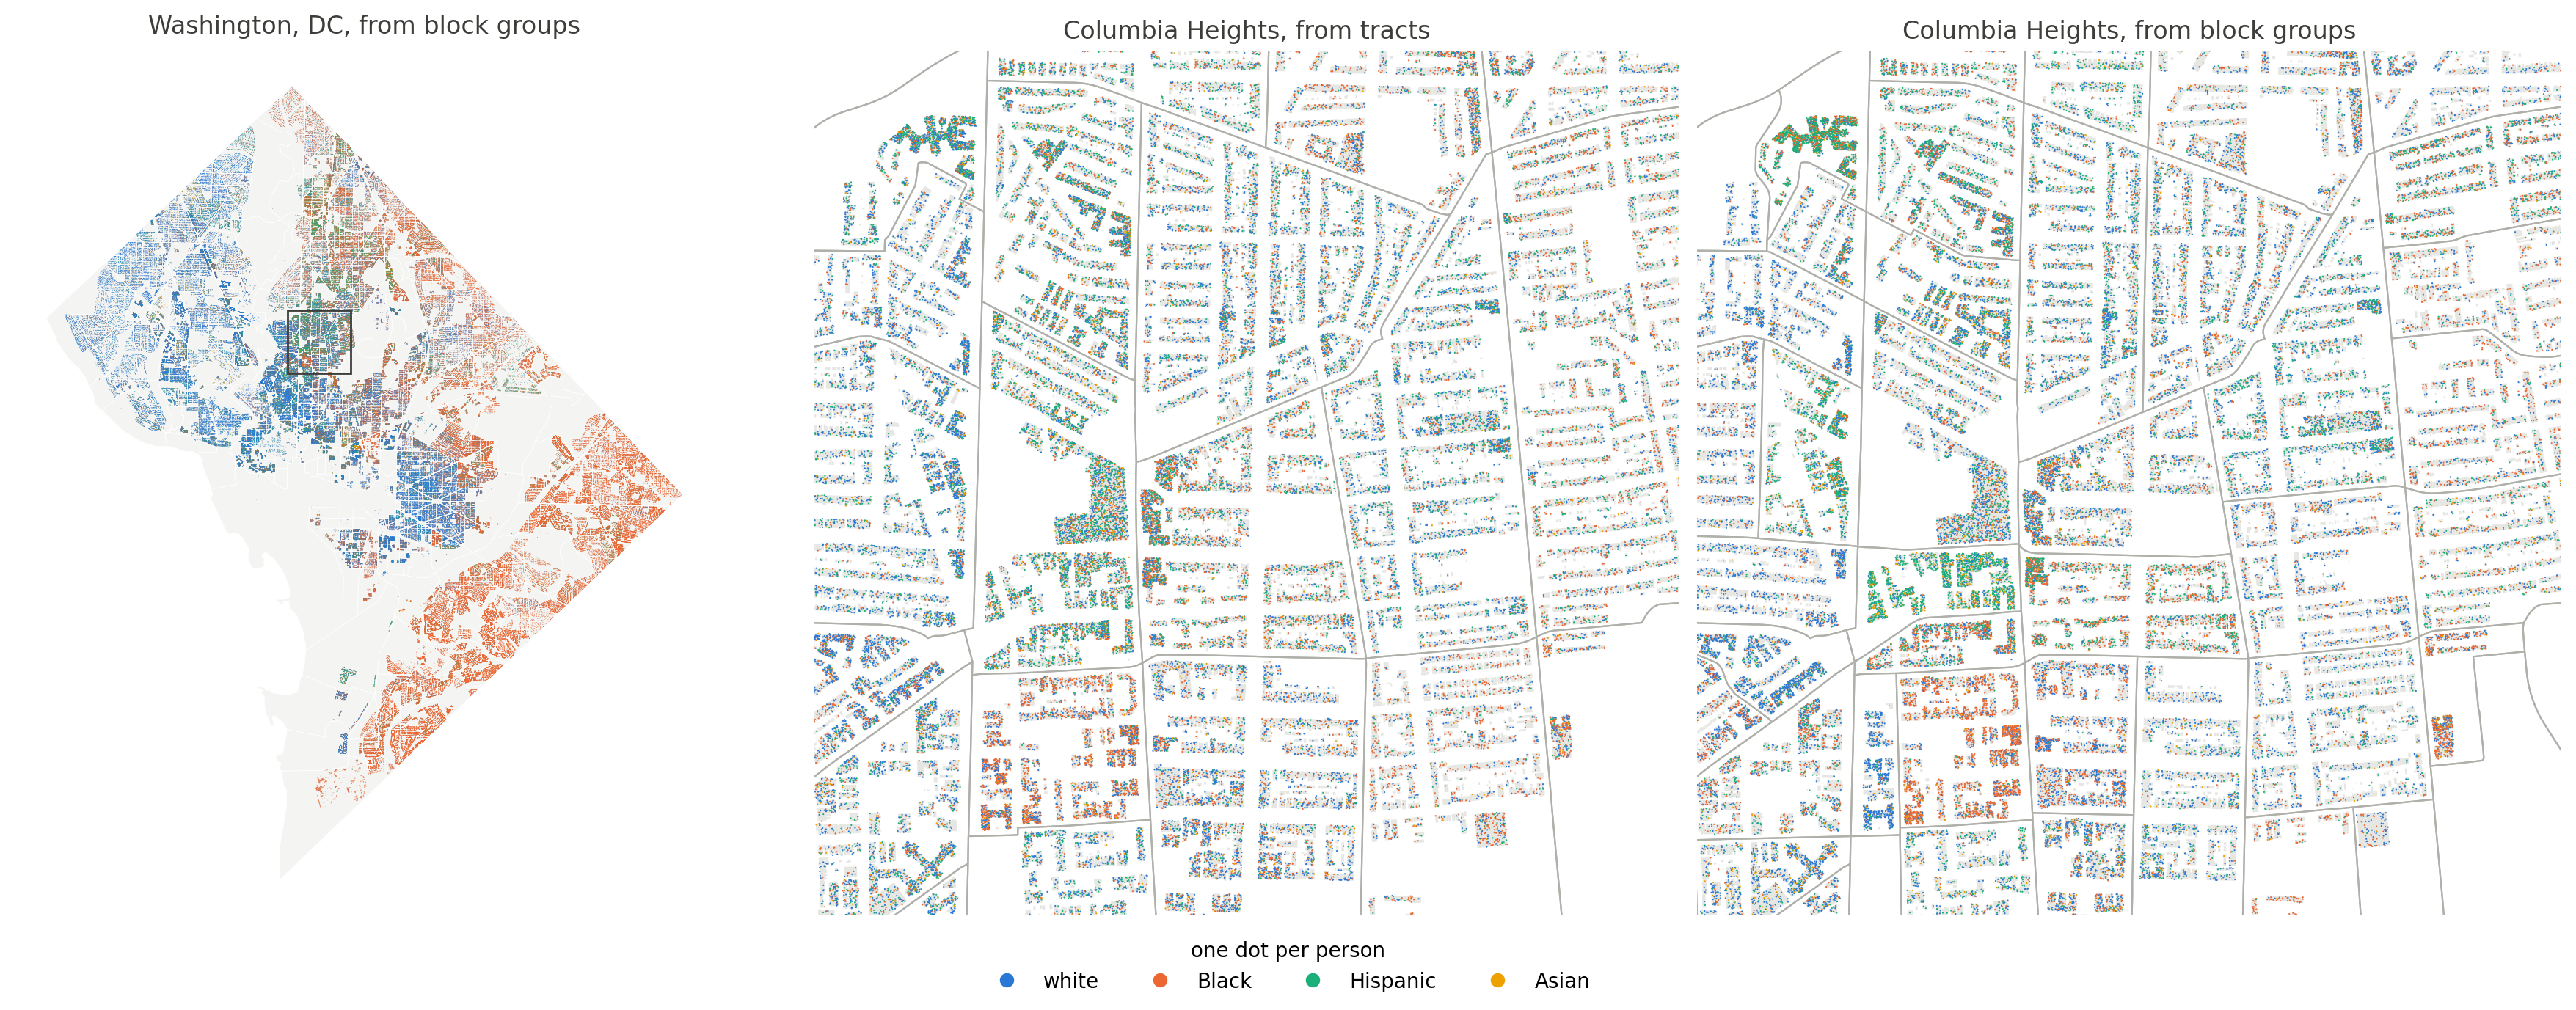

In [19]:
groups = {
    "n_nonhisp_white_persons": "white",
    "n_nonhisp_black_persons": "Black",
    "n_hispanic_persons": "Hispanic",
    "n_asian_persons": "Asian",
}
group_colors = dict(zip(groups.values(), colors.values()))
dots = {
    source: floor_area_dot_density(
        units, dc_bldgs, list(groups), **gaps_filled, rng=0
    ).sample(frac=1, random_state=0)  # shuffle, so no group is drawn on top of the others
    for source, units in {"tracts": dc_tracts, "block groups": dc_bgs}.items()
}

center = gpd.GeoSeries(gpd.points_from_xy([-77.030], [38.930]), crs=4326).to_crs(dc_bgs.crs)
x0, y0 = center.x.iloc[0] - 900, center.y.iloc[0] - 900
x1, y1 = x0 + 1800, y0 + 1800


def draw(ax, d, size):
    ax.scatter(
        d.geometry.x,
        d.geometry.y,
        s=size,
        c=d["category"].map(groups).map(group_colors),
        lw=0,
        rasterized=True,
    )
    ax.set_axis_off()


fig, axes = plt.subplots(1, 3, figsize=(18, 6.8), layout="constrained")
dc_bgs.plot(ax=axes[0], color="#f4f4f2", edgecolor="white", lw=0.3)
draw(axes[0], dots["block groups"], 0.05)
axes[0].add_patch(Rectangle((x0, y0), x1 - x0, y1 - y0, fill=False, ec=ink, lw=1))
axes[0].set_title("Washington, DC, from block groups", color=ink)
for ax, (source, units) in zip(axes[1:], {"tracts": dc_tracts, "block groups": dc_bgs}.items()):
    dc_bldgs.cx[x0:x1, y0:y1].plot(ax=ax, color=grid, lw=0)
    units.boundary.plot(ax=ax, color="#b0b0ab", lw=0.8)
    draw(ax, dots[source].cx[x0:x1, y0:y1], 0.6)
    ax.set(xlim=(x0, x1), ylim=(y0, y1))
    ax.set_title(f"Columbia Heights, from {source}", color=ink)
handles = [Line2D([], [], marker="o", ls="", color=c, label=g) for g, c in group_colors.items()]
fig.legend(
    handles=handles, loc="outside lower center", ncols=4, frameon=False, title="one dot per person"
)
plt.show()

Both maps put every resident inside a residential building, which is why both look plausible at this scale. They differ in the mix of groups. With tracts as the source, every building in a tract has the same expected mix, so the mix changes only at tract boundaries. With block groups as the source, it can change from one block group to the next. In the lower left of the Columbia Heights maps, a block group of mostly Hispanic residents sits just north of a mostly Black one, and a narrow block group of mostly white residents runs along the latter's western edge; the tract map blends the three.

The detail is reliable only down to the block group. Within each block group the dots follow floor area, and the block test above, run on the 2020 counts rather than the ACS counts mapped here, indicates what that costs: even from block groups, the best weight puts 15.4% of DC's housing units in the wrong block. A building-level map is more precise in its geometry than in its counts, though each block group's residents stay inside it.

## Caveats

- The block-group "truth" is itself a survey estimate. ACS block-group estimates carry sizeable margins of error, so part of every method's measured error is sampling noise in the benchmark.
- Overture heights vary in source and quality, and a fixed three-meter floor height is a coarse assumption. Where most buildings are one or two stories, as in Delaware, floor area can differ little from footprint area.
- How a missing height is counted matters wherever heights are missing unevenly. In DC they are missing mostly from small buildings, so counting a missing height as one floor shifts weight toward the larger buildings that have one.
- The land-use filter is only as good as OpenStreetMap's land-use mapping. Unclassified offices and hotels outside a mapped commercial area still receive residents in proportion to their floor area, and the filter drops some real housing, such as dormitories, housing on military land, and apartments above shops in commercial areas.
- The block test uses 2020 census counts rather than the ACS. Noise added to the block population counts for disclosure avoidance inflates every method's measured error for population; the block housing-unit counts carry no such noise.